# 06A — Combine → NFL transfer: cohort and leakage audit

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing in this notebook has been run by its author; no number below exists until you run it.

**Programme question (Milestone 06).** When two prospects have similar official Combine results, does high-frequency Combine tracking reveal a repeatable movement characteristic that helps predict how they will move during NFL games?

**This notebook answers a narrower, earlier question:** *on exactly which athletes, labels and folds can that be tested without leakage?* It fits no prediction model and computes no association between a Combine value and an NFL value.

| Step | What is established | Stops the study when |
|---|---|---|
| Outcome freeze audit | the NFL targets were frozen by notebook 05B, before any Combine association | the registry is absent, pending, `STOP`, incomplete or altered |
| Identity integrity | one canonical athlete id, one Combine ↔ NFL link | (conflicting athletes are excluded and listed, never repaired) |
| Cohort funnel | the primary cohort supporting every model M0–M7 | fewer athletes than the declared minimum |
| Split integrity | athlete-grouped outer folds, all attempts and seasons of an athlete together | no viable fold design |
| Representation leakage audit | which saved FPCA / TCN fits may be reused under these folds | (others are marked descriptive-only and refitted in 06B) |

**Hypotheses, registered here before any transfer result exists.** Primary: *a repeatable Combine movement representation contains information about realized NFL movement that official Combine testing and pre-draft anthropometrics do not capture.*

- H1 — interpretable Combine speed-development measures predict NFL sustained acceleration beyond official testing (M2 vs M1).
- H2 — TCN-B embeddings improve NFL acceleration prediction over official tests alone (M5 vs M1). **This is the primary comparison.**
- H3 — any TCN-B improvement remains after a simple speed representation is included (M1 + SPEED2 + TCN-B vs M3).
- H4 — transfer differs by position and observed NFL context *(secondary / exploratory)*.
- H5 — conclusions keep their direction under reasonable exposure and measurement-quality changes *(secondary)*.
- H6 — among similarly timed prospects, learned movement differences help predict NFL movement differences *(secondary)*.

No causal effect and no coaching prescription is claimed anywhere in this milestone.

**How to run.** Notebooks 00–05B must have been run in the same `RUN_MODE`. Run top to bottom with `RUN_MODE = 'smoke'` (wiring check), restart the kernel, then `'full'`. PyTorch is needed (saved encoders are opened to read which athletes they were fitted on). If section 2 stops with `TargetFreezeError`, that is the designed behaviour: record the freeze in `05b_nfl_outcome_reliability_and_freeze.ipynb` section 10 and come back.

In [14]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'       # 'smoke' | 'full' — must match the mode notebooks 00–05B were run with
FORCE_REBUILD = False    # the audit is cheap and always recomputed; kept for symmetry with the other notebooks
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True       # unused here (no model is fitted)
SEED = 20261011          # same seed as notebook 00
DEVICE = 'cpu'           # saved encoders are only opened, never trained, in this notebook

FOLD_SOURCE = 'auto'     # 'auto' = reuse the notebook-00 split registry when its folds are viable in the linked cohort,
                         #          otherwise deal new folds · 'registry' · 'new'. Decided on athlete counts only.

## 0. Setup

In [15]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)    # thread and memory limits; call before the first polars import of the kernel

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import read_json, utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import fpca as fp
from nflbdb.research.advanced_movement import fpca_eval as fe
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import repr_eval as rv
from nflbdb.research.advanced_movement import robust as rb
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement import transfer_figures as tf
from nflbdb.research.advanced_movement import transfer_validation as tv
from nflbdb.research.advanced_movement.artifacts import TransferStore
from nflbdb.research.contracts import conform

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                save_models=SAVE_MODELS, device=DEVICE, seed=SEED).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
tc = tr.TransferConfig().for_mode(controls)
store = TransferStore(cfg, controls)      # writes under .../advanced_movement/transfer (smoke: .../_sample/transfer)
up = store.upstream                       # notebooks 00–03, read only · store.atlas = Milestone 04 · store.nfl = Milestone 05
amc.seed_everything(controls.seed)

NB = {'00': '00_research_setup_and_data_audit.ipynb', '01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb',
      '03': '03_self_supervised_tcn.ipynb', '04A': '04a_feature_characteristic_atlas.ipynb', '04B': '04b_tcn_robustness_and_shortlist.ipynb',
      '05A': '05a_nfl_movement_outcome_eda.ipynb', '05B': '05b_nfl_outcome_reliability_and_freeze.ipynb'}
PRIMARY_INPUT = 'A_speed_by_distance'     # the input of the frozen FPCA benchmark and of TCN-B
STAGE = '06A'
PROV = {'notebook': '06a_transfer_cohort_and_leakage_audit.ipynb', 'run_mode': controls.run_mode, 'seed': controls.seed,
        'transfer_config': tc.params()}

def save(df, contract):
    '''Validate against the contract and persist (Parquet + sidecar, CSV for small tables) unless SAVE_TABLES is off.'''
    return store.write(df, contract, STAGE, PROV) if controls.save_tables else conform(df, contract)

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label})'))
display(store.describe())
display(pl.DataFrame([{'parameter': k, 'value': str(v)} for k, v in tc.params().items()]))

**Run mode: `full`** (FULL)

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


parameter,value
str,str
"""version""","""1"""
"""seed""","""20261011"""
"""core_official""","""('cmb_forty', 'cmb_ten_yd_spli…"
"""height""","""cmb_combine_height"""
"""optional_tests""","""('cmb_vertical', 'cmb_broad_ju…"
…,…
"""horizon_seasons""","""(1,)"""
"""play_classes""","""('pass', 'no_pass')"""
"""min_relative_gain""","""0.02"""


## 1. Synthetic validation of the audit code

Seven checks on data with a known answer (athlete linkage, duplicate detection, cohort eligibility, target-freeze enforcement, athlete-grouped splitting, checkpoint compatibility, artifact version consistency). They run in-process, write only inside a temporary directory and never touch the warehouse. **Every row must read `PASS`.** A failing row is a defect of the code or of a tolerance set without running it: send the table, do not loosen the check.

In [16]:
validation_report = tv.run_all(tv.CHECKS_06A)
with pl.Config(tbl_rows=30, fmt_str_lengths=220):
    display(validation_report)
tv.assert_all_passed(validation_report)

11:10:13 | INFO    | nflbdb.research.advanced_movement.outcome_reliability | [nfl_outcomes] nfl_movement_targets_v1.json written: decision STOP, targets []
11:10:13 | INFO    | nflbdb.research.advanced_movement.outcome_reliability | [nfl_outcomes] nfl_movement_targets_v1.json written: decision FREEZE, targets ['O2.accel_sust05_mean', 'O1.speed_p90_mean']


check,status,detail
str,str,str
"""athlete_linkage""","""PASS""","""a clean linkage passes; a position conflict, a cohort conflict and an NFL window before the draft year are excluded and listed"""
"""duplicate_athlete_detection""","""PASS""","""a duplicated mart row and an attempt without an athlete are critical; a shared display name is reported and never used to link"""
"""cohort_eligibility""","""PASS""","""each athlete leaves the funnel at the first rule he fails; the funnel is monotone and ends at the primary cohort; an athlete without tracking stays in the wide cohort; mandatory, imputed and excluded predictors follow co…"
"""target_freeze_enforcement""","""PASS""","""an absent, pending or STOP registry blocks the study; a FREEZE written by notebook 05B passes; an edited formula, a re-ordered target list, another run mode or a re-freeze after a transfer run are each detected; nothing …"
"""athlete_grouped_splitting""","""PASS""","""one outer fold per athlete; registry folds are reused when viable, otherwise the largest viable K is dealt within position × cohort; unlinked athletes are never held out under new folds; a too-small cohort raises instead…"
"""checkpoint_compatibility""","""PASS""","""a saved fit is reusable only for its own fold of split repeat 0 and only if no athlete held out there took part in it; all-athlete fits, other repeats and every fit under new folds are descriptive-only; an unfrozen regis…"
"""artifact_version_consistency""","""PASS""","""06B and 06C refuse to start when the frozen targets, the fold table or the 06A gate differ from what the cohort audit recorded"""


## 2. Outcome freeze audit — the first gate

The transfer study may only predict NFL outcomes that were **frozen before any Combine association was looked at**. The authoritative record is `nfl_movement_targets_v1.json`, written once by notebook 05B section 10 when `DECISION = 'FREEZE'` is recorded.

A *proposed* shortlist is not a frozen registry. The cell below verifies status, target ids, formulas, units, context definition, exposure requirement, inclusion rules, smoothing rule, definition and version hashes, selection justification, reliability evidence and provenance. If any check fails it shows the blocker — and, for information only, the rule-based proposal of 05B — and **raises**. Nothing is defaulted, and this notebook cannot write the registry: a freeze recorded after a look at transfer results would not be a freeze.

In [17]:
prior = (read_json(store.data_dir / (tr.AUDIT_MANIFEST + '.json'), {}) or {}).get('targets_version_hash')
registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode, prior_hash=prior)
with pl.Config(tbl_rows=20, fmt_str_lengths=260):
    display(freeze_audit)

if freeze_audit.filter(~pl.col('passed')).height:
    review = tr.proposal_for_review(store.nfl)
    display(Markdown('### BLOCKER — the NFL targets are not frozen\n'
                     f'Registry expected at `{cfg.paths.rel(tr.targets_path(store.nfl))}`.\n\n'
                     f'For review only — what notebook 05B recorded: decision `{review["recorded_decision"]}`, '
                     f'gate 05 `{review["gate_05"]}`, message: {review["freeze_message"]}.\n\n'
                     f'Rule-based PROPOSAL of 05B (not a freeze): `{review["proposal"]}`\n\n'
                     'Open `05b_nfl_outcome_reliability_and_freeze.ipynb`, review the full run, set `DECISION`, `PRIMARY`, `SECONDARY`, '
                     '`RATIONALE` in section 10, rerun that cell, then rerun this notebook.'))
tr.assert_frozen(freeze_audit)            # raises TargetFreezeError when a check failed: no cell below may run

targets, ocfg = tr.frozen_targets(registry_doc)
primary = tr.primary_target(targets)
display(Markdown(f'**Frozen on {registry_doc["frozen_at"]}** · version hash `{registry_doc["version_hash"]}` · primary target '
                 f'`{primary.target_id}` · outcome definition hash `{no.definition_hash(ocfg)}`'))
with pl.Config(fmt_str_lengths=200):
    display(pl.DataFrame([{'target_id': t.target_id, 'frozen_rank': t.rank, 'role_in_this_study': t.study_role, 'label': t.label,
                           'unit': t.unit, 'athlete_statistic': t.stat, 'context_adjustment': t.adjustment,
                           'min_windows': t.min_windows, 'definition_hash': t.definition_hash} for t in targets]))
    display(pl.DataFrame([{'target_id': str(t['outcome_id']), 'formula': str(t['formula']), 'window': str(t['window']),
                           'inclusion_exclusion': str(t['inclusion_exclusion']), 'smoothing': str(t['smoothing']),
                           'reliability': str(t['reliability'])} for t in registry_doc['targets']]))
display(Markdown(f'**Selection rationale recorded in 05B:** {registry_doc["selection"].get("rationale") or "(follows the rule-based proposal)"}'))

check,passed,detail
str,bool,str
"""registry_present""",true,"""nfl_movement_targets_v1.json found"""
"""status_is_freeze""",true,"""decision = 'FREEZE' (frozen at 2026-10-13T11:09:49Z)"""
"""targets_listed""",true,"""3 target(s), ranks ['primary', 'secondary', 'secondary']"""
"""target_fields_complete""",true,"""every target carries target ID, exact formula, units, context definition, exposure requirement, inclusion / exclusion rules, smoothing rule, definition hash, reliability evidence"""
"""definition_hashes_reproduce""",true,"""each definition hash equals the hash of the stored definition"""
"""version_hash_reproduces""",true,"""stored 8ff9fc191616711a, recomputed 8ff9fc191616711a"""
"""selection_justified""",true,"""written rationale"""
"""reliability_evidence""",true,"""O2.accel_sust05_mean: 0.9316490339648935; O3.band_acc_v0_2_mean: 0.9215933569966047; O1.speed_p90_mean: 0.9001097152147467"""
"""provenance_recorded""",true,"""keys ['definition_hash', 'inputs', 'n_athletes', 'n_eligible_windows', 'notebook', 'play_table_notebook', 'run_mode', 'seed', 'source_tables']"""


**Frozen on 2026-10-13T11:09:49Z** · version hash `8ff9fc191616711a` · primary target `O2.accel_sust05_mean` · outcome definition hash `dd9610142ae88344`

target_id,frozen_rank,role_in_this_study,label,unit,athlete_statistic,context_adjustment,min_windows,definition_hash
str,str,str,str,str,str,str,i64,str
"""O2.accel_sust05_mean""","""primary""","""primary""","""sustained acceleration, 0.5 s (mean of windows)""","""yd/s²""","""mean""","""cell_residual""",50,"""8d2379a4ace038fe"""
"""O3.band_acc_v0_2_mean""","""secondary""","""secondary_speed_conditioned""","""acceleration from 0–2 yd/s (mean of windows)""","""yd/s²""","""mean""","""none""",50,"""9db83447f033153e"""
"""O1.speed_p90_mean""","""secondary""","""secondary_speed""","""play p90 speed (mean of windows)""","""yd/s""","""mean""","""none""",50,"""380f7c40ed7011a7"""


target_id,formula,window,inclusion_exclusion,smoothing,reliability
str,str,str,str,str,str
"""O2.accel_sust05_mean""","""mean over eligible windows of max_t mean(a_tan[t, t + 0.5 s])""","""0.5 s, post-snap""","""quality tier in ['A', 'B']; ≥ 15 valid post-snap frames; not nullified by penalty; windows touching filter-edge frames excluded""","""Savitzky–Golay window 7 frames, order 2 (KinematicsConfig v1)""","""{'context_adjusted': 0.843402050653876, 'estimate': 0.9316490339648935, 'first_windows_vs_later_games_r': 0.7498029137082194, 'method': 'random game half-splits, Spearman–Brown, within position', 'min…"
"""O3.band_acc_v0_2_mean""","""mean over eligible windows of mean_t [(speed(t + 0.5 s) − speed(t)) / 0.5 s] over start frames with speed in [0, 2) and a positive change (≥ 3 such frames)""","""0.5 s, post-snap""","""quality tier in ['A', 'B']; ≥ 15 valid post-snap frames; not nullified by penalty; windows touching filter-edge frames excluded""","""Savitzky–Golay window 7 frames, order 2 (KinematicsConfig v1)""","""{'context_adjusted': 0.8494630368075673, 'estimate': 0.9215933569966047, 'first_windows_vs_later_games_r': 0.7510127241121254, 'method': 'random game half-splits, Spearman–Brown, within position', 'mi…"
"""O1.speed_p90_mean""","""mean over eligible windows of the 90th percentile of post-snap frame speeds""","""whole post-snap window""","""quality tier in ['A', 'B']; ≥ 15 valid post-snap frames; not nullified by penalty; windows touching filter-edge frames excluded""","""Savitzky–Golay window 7 frames, order 2 (KinematicsConfig v1)""","""{'context_adjusted': 0.8581450270432514, 'estimate': 0.9001097152147467, 'first_windows_vs_later_games_r': 0.7233112180218346, 'method': 'random game half-splits, Spearman–Brown, within position', 'mi…"


**Selection rationale recorded in 05B:** Primary O2 is a physically interpretable sustained-acceleration outcome with strong across-game reliability and broad athlete coverage. O3 evaluates acceleration conditional on low starting speed, while O1 provides a robust realized-speed control. These targets were selected using measurement reliability, coverage, physical interpretation and context diagnostics, without examining their associations with Combine features. The movement envelope O5 remains exploratory because of lower coverage.

## 3. Input contracts

Everything is read from persisted Gold tables of the same run mode; no tracking frame is reprocessed. The play table of notebook 05A is the only NFL input, and it is used here for **exposure counts only**.

| Input | Written by | Used for |
|---|---|---|
| athlete registry, sequence manifest, split registry | 00 | identity, eligible attempts, candidate folds |
| sequence frames, window flags, FPCA summary | 01, 02 | the curves every encoder reads; benchmark K |
| feature dictionary, attempt features | 04A | frozen engineered features and the speed control |
| frozen shortlist `transfer_candidates_v1` | 04B | exact candidate feature ids — no atlas exploration |
| research mart (official results) | Phase 01 | official tests and body measurements |
| `nfl_play_movement`, target registry | 05A, 05B | NFL exposure and the frozen labels |

In [18]:
manifest = up.require(amd.MANIFEST, NB['00'])
athletes = up.require(amd.ATHLETES, NB['00'])
splits = up.require(amd.SPLITS, NB['00'])
seq_frames = up.require(seq.SEQ_FRAMES, NB['01'])
windows = up.require(ck.WINDOWS, NB['02'])
fpca_summary = up.require(fe.SUMMARY, NB['02'])
dictionary = store.atlas.require(at.DICTIONARY, NB['04A'])
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
shortlist = store.atlas.require(rb.SHORTLIST, NB['04B'])
PLAYS = no.plays_contract(ocfg)
plays = store.nfl.require(PLAYS, NB['05A'])
mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
official = at.official_table(mart, athletes)

families = tr.frozen_feature_ids(shortlist)
K = {r['representation']: int(r['k_selected']) for r in fpca_summary.iter_rows(named=True)}
FPCA_K = K[PRIMARY_INPUT]
problems = []
if families['FPCA'] != rv.fpca_method(PRIMARY_INPUT, FPCA_K).method:
    problems.append(f'shortlist FPCA candidate {families["FPCA"]} is not the benchmark of notebook 02 ({rv.fpca_method(PRIMARY_INPUT, FPCA_K).method})')
if families['TCN'] != 'TCNB_A':
    problems.append(f'shortlist encoder candidate is {families["TCN"]}, expected the primary TCN-B on input A')
known = set(attempt_values['feature_id'].unique().to_list())
absent = [f for f in [*families['ENG'], *families['SPEED2']] if f not in known]
if absent:
    problems.append(f'frozen feature id(s) absent from the atlas attempt table: {absent}')
if problems:
    raise tr.TransferGateError('frozen candidate registry cannot be honoured — ' + '; '.join(problems))

rel = cfg.paths.rel
target_rows = pl.DataFrame({'outcome_id': [t.target_id for t in targets], 'rank': [t.rank for t in targets]})
inputs = [
    tr.describe_input('athlete_registry', up.parquet(amd.ATHLETES), athletes, ['nfl_id', 'position_group', 'draft_year', 'n_primary_eligible', *amd.OFFICIAL], 'Combine roster and identity', rel),
    tr.describe_input('sequence_manifest', up.parquet(amd.MANIFEST), manifest, ['seq_id', 'nfl_id', 'eligible_primary'], 'eligible Combine attempts', rel),
    tr.describe_input('split_registry', up.parquet(amd.SPLITS), splits, ['nfl_id', 'repeat', 'outer_fold', 'inner_fold'], 'candidate folds; folds of the saved encoders', rel),
    tr.describe_input('sequence_frames', up.parquet(seq.SEQ_FRAMES), seq_frames, ['seq_id', 'nfl_id', 'frame'], 'curves read by FPCA and TCN-B', rel),
    tr.describe_input('sequence_window_flags', up.parquet(ck.WINDOWS), windows, ['seq_id', 'nfl_id', 'attempt_order', 'S2_signal'], 'attempt order and signal quality', rel),
    tr.describe_input('fpca_representation_summary', up.parquet(fe.SUMMARY), fpca_summary, ['representation', 'k_selected'], 'benchmark K', rel),
    tr.describe_input('feature_dictionary', store.atlas.parquet(at.DICTIONARY), dictionary, ['feature_id', 'units', 'definition'], 'definition of the frozen features', rel),
    tr.describe_input('atlas_attempt_features', store.atlas.parquet(at.ATTEMPT_VALUES), attempt_values, ['feature_id', 'seq_id', 'nfl_id', 'value', 'missing_reason'], 'engineered features and speed control per attempt', rel),
    tr.describe_input('transfer_candidates_v1', store.atlas.parquet(rb.SHORTLIST), shortlist, ['candidate_id', 'selected', 'features', 'readiness'], 'frozen Combine candidate registry', rel),
    tr.describe_input('mart_athlete_research_base', None, mart, ['nfl_id', *tc.core_official], 'official Combine measurements', rel),
    tr.describe_input('nfl_play_movement', store.nfl.parquet(PLAYS), plays, ['nfl_id', 'game_id', 'season', 'eligible', 'position_group', 'cohort'], 'NFL windows behind the frozen labels (exposure only in 06A)', rel),
    tr.describe_input('nfl_movement_targets_v1', tr.targets_path(store.nfl), target_rows, ['outcome_id', 'rank'], 'frozen NFL target registry', rel)]
tr.assert_inputs(inputs)
with pl.Config(tbl_rows=20, fmt_str_lengths=120):
    display(pl.DataFrame([{k: str(e[k]) for k in ('name', 'role', 'rows', 'path', 'missing_columns')} for e in inputs]))
display(Markdown('**Frozen candidate families carried into the transfer models** (exact ids of the shortlist)'))
with pl.Config(fmt_str_lengths=160):
    display(pl.DataFrame([{'model': 'M2 engineered movement', 'features': '; '.join(families['ENG']) or 'EMPTY SLOT — M2 cannot be evaluated'},
                          {'model': 'M3 SPEED2 control', 'features': '; '.join(families['SPEED2'])},
                          {'model': 'M4 FPCA', 'features': f'{families["FPCA"]} (K = {FPCA_K}, refitted on each training fold)'},
                          {'model': 'M5 TCN-B', 'features': f'{families["TCN"]} (8-d, fold encoders)'},
                          {'model': 'M7 compact TCN', 'features': f'frozen compact dimension {families["COMPACT"]}; dims evaluated {list(tc.compact_dims)} (exploratory, none selected)'}]))
    display(dictionary.filter(pl.col('feature_id').is_in([*families['ENG'], *families['SPEED2']])).select('feature_id', 'units', 'definition', 'time_or_distance_window'))

name,role,rows,path,missing_columns
str,str,str,str,str
"""athlete_registry""","""Combine roster and identity""","""510""","""warehouse/gold/advanced_movement/athlete_registry.parquet""","""[]"""
"""sequence_manifest""","""eligible Combine attempts""","""6310""","""warehouse/gold/advanced_movement/sequence_manifest.parquet""","""[]"""
"""split_registry""","""candidate folds; folds of the saved encoders""","""1254""","""warehouse/gold/advanced_movement/split_registry.parquet""","""[]"""
"""sequence_frames""","""curves read by FPCA and TCN-B""","""41500""","""warehouse/gold/advanced_movement/sequence_frames.parquet""","""[]"""
"""sequence_window_flags""","""attempt order and signal quality""","""793""","""warehouse/gold/advanced_movement/sequence_window_flags.parquet""","""[]"""
"""fpca_representation_summary""","""benchmark K""","""6""","""warehouse/gold/advanced_movement/fpca_representation_summary.parquet""","""[]"""
"""feature_dictionary""","""definition of the frozen features""","""1409""","""warehouse/gold/advanced_movement/atlas/feature_dictionary.parquet""","""[]"""
"""atlas_attempt_features""","""engineered features and speed control per attempt""","""31720""","""warehouse/gold/advanced_movement/atlas/atlas_attempt_features.parquet""","""[]"""
"""transfer_candidates_v1""","""frozen Combine candidate registry""","""7""","""warehouse/gold/advanced_movement/atlas/transfer_candidates_v1.parquet""","""[]"""


**Frozen candidate families carried into the transfer models** (exact ids of the shortlist)

model,features
str,str
"""M2 engineered movement""","""F6.forty.time_v4_to_v8_s"""
"""M3 SPEED2 control""","""F2.forty.p95_speed; F2.forty.peak_speed_interior"""
"""M4 FPCA""","""FPCA_A_K2 (K = 2, refitted on each training fold)"""
"""M5 TCN-B""","""TCNB_A (8-d, fold encoders)"""
"""M7 compact TCN""","""frozen compact dimension 4; dims evaluated [2, 4] (exploratory, none selected)"""


feature_id,units,definition,time_or_distance_window
str,str,str,str
"""F2.forty.p95_speed""","""yd/s""","""95th percentile of speed (valid frames)""","""whole recording"""
"""F2.forty.peak_speed_interior""","""yd/s""","""max speed over valid frames NOT in the SG filter boundary (edge distance < window // 2)""","""whole recording"""
"""F6.forty.time_v4_to_v8_s""","""s""","""time between the first crossings of 4 and 8 yd/s (defined only when both crossings are recorded)""","""4 → 8 yd/s"""


## 4. Athlete identity integrity

`nfl_id` is the only key used to link the Combine and the NFL; names are never used. Critical checks: one mart row and one registry row per athlete, a known Combine position and draft year, the same position group and draft cohort on the NFL side, no regular-season window before the draft year, every eligible attempt attached to a registry athlete. **An athlete failing a critical check is excluded from every cohort and listed below; nothing is resolved silently.** Informational checks (an NFL athlete without a Combine row, a shared display name) are reported.

In [19]:
tset = tr.TargetSet(plays, ocfg, targets)
exposure = tset.exposure()
identity, bad_identity = tr.identity_audit(athletes, mart, exposure, manifest, ocfg.positions)
identity = save(identity, tr.IDENTITY)
with pl.Config(tbl_rows=20, fmt_str_lengths=220):
    display(identity)
unlinked = exposure.join(athletes.select('nfl_id'), on='nfl_id', how='anti')
display(Markdown(f'**{exposure.height} athletes with an eligible NFL window · {exposure.height - unlinked.height} linked to a Combine registry row · '
                 f'{unlinked.height} not linked (left out, not guessed) · {len(bad_identity)} excluded for an identity conflict**'))
if bad_identity:
    display(athletes.filter(pl.col('nfl_id').is_in(sorted(bad_identity))).select('nfl_id', 'display_name', 'position_group', 'draft_year')
            .join(pl.DataFrame({'nfl_id': list(bad_identity), 'failed_check': list(bad_identity.values())}), on='nfl_id', how='left')
            .join(exposure.select('nfl_id', 'nfl_position_group', 'nfl_cohort', 'first_season'), on='nfl_id', how='left'))

11:10:14 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_identity_audit: 11 rows → warehouse/gold/advanced_movement/transfer/transfer_identity_audit.parquet


check,severity,passed,n_violations,detail
str,str,bool,i64,str
"""unique_mart_row""","""critical""",true,0,"""one row per athlete in gold.mart_athlete_research_base"""
"""unique_registry_row""","""critical""",true,0,"""one row per athlete in the athlete registry of notebook 00"""
"""position_known""","""critical""",true,0,"""Combine position group recorded for every tracked athlete"""
"""position_in_scope""","""info""",true,0,"""Combine position group among ['DB', 'DL', 'OL', 'TE', 'WR'] (others cannot have an NFL target)"""
"""draft_year_known""","""critical""",true,0,"""draft cohort recorded for every tracked athlete"""
"""nfl_athlete_in_registry""","""info""",true,0,"""every NFL-tracked athlete has a Combine registry row (others cannot be linked and are left out)"""
"""same_position_group""","""critical""",true,0,"""Combine position group = position group of the NFL play table"""
"""same_draft_cohort""","""critical""",true,0,"""draft year of the registry = cohort of the NFL play table"""
"""nfl_after_combine""","""critical""",true,0,"""no regular-season window before the athlete's draft year (the predictors are pre-NFL)"""


**401 athletes with an eligible NFL window · 401 linked to a Combine registry row · 0 not linked (left out, not guessed) · 0 excluded for an identity conflict**

## 5. Target grain and exposure

**Grain of the primary study: one label per athlete.** The label is the frozen athlete statistic over all his eligible regular-season windows (every tracked season pooled), and the athlete needs at least the frozen number of windows. Athlete-seasons are never rows: several seasons of one athlete are one label, in one fold.

| Grain | Use in Milestone 06 |
|---|---|
| athlete, all eligible windows | **primary** (the frozen definition) |
| athlete, first N eligible windows in time | sensitivity in 06C (`first_n`) |
| athlete, seasons within a common post-draft horizon | sensitivity in 06C (`horizon`) |
| athlete-season, athlete-game | not modelled (they are not independent athletes) |

The table below holds **exposure counts only**. No label value leaves `TargetSet` in this notebook.

In [20]:
eligibility = save(tset.eligibility(), tr.ELIGIBILITY)
pos_of = tset.eng.athletes.select('nfl_id', 'position_group')
summary = (eligibility.join(pos_of, on='nfl_id', how='left').group_by('target_id', 'study_role', 'min_windows', 'position_group')
           .agg(pl.len().alias('n_tracked'), pl.col('eligible').sum().alias('n_meeting_exposure'), pl.col('n_windows').median().alias('median_windows'),
                pl.col('n_games').median().alias('median_games')).sort('target_id', 'position_group'))
display(Markdown('**Athletes meeting the frozen exposure requirement, by target and position group** (unit: athlete)'))
with pl.Config(tbl_rows=40):
    display(summary)

11:10:16 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_target_eligibility: 1,203 rows → warehouse/gold/advanced_movement/transfer/transfer_target_eligibility.parquet


**Athletes meeting the frozen exposure requirement, by target and position group** (unit: athlete)

target_id,study_role,min_windows,position_group,n_tracked,n_meeting_exposure,median_windows,median_games
str,str,i64,str,u32,u32,f64,f64
"""O1.speed_p90_mean""","""secondary_speed""",50,"""DB""",96,78,416.5,15.0
"""O1.speed_p90_mean""","""secondary_speed""",50,"""DL""",98,88,289.5,17.0
"""O1.speed_p90_mean""","""secondary_speed""",50,"""OL""",91,77,747.0,15.0
"""O1.speed_p90_mean""","""secondary_speed""",50,"""TE""",33,23,183.0,17.0
"""O1.speed_p90_mean""","""secondary_speed""",50,"""WR""",83,70,292.0,17.0
"""O2.accel_sust05_mean""","""primary""",50,"""DB""",96,78,415.5,15.0
"""O2.accel_sust05_mean""","""primary""",50,"""DL""",98,88,289.5,17.0
"""O2.accel_sust05_mean""","""primary""",50,"""OL""",91,77,746.0,15.0
"""O2.accel_sust05_mean""","""primary""",50,"""TE""",33,23,183.0,17.0


## 6. Analytical cohort funnel

Each rule is applied in a fixed order; an athlete leaves at the first rule he fails, with that rule as his recorded reason.

1. Combine roster → 2. eligible tracked forty → 3. official core (forty, 10-yard split, weight) → 4. frozen engineered features and speed control measured → 5. FPCA input → 6. TCN input (the same curve) → 7. NFL regular-season tracking → 8. frozen exposure requirement of the primary target → 9. **primary cohort** (and a consistent identity).

- **Primary cohort** — supports every model M0–M7. All paired comparisons use these athletes and one label each. Membership depends on *availability* only: no NFL label value and no prediction error enters it.
- **Wide cohort** — official core + target exposure, tracking not required. Used in 06B for a separately labelled analysis of M0 / M1 only.
- Stages 5–6 are checked here on the recorded curve; whether a fold's encoder can embed an attempt also depends on that fold's support and is re-checked in 06B (`common_support`), where an athlete without an embedding is dropped — never imputed.

In [21]:
from nflbdb.research.advanced_movement import transfer_repr as trp      # imports PyTorch (the TCN module)

ss = seq.SequenceSet.from_frames(seq_frames, manifest)
curves = fp.build_curves(ss, acfg, fp.SPEC[PRIMARY_INPUT])
cohort = save(tr.cohort_manifest(athletes, official, attempt_values, trp.curve_rows(curves), windows, exposure, eligibility, primary,
                                 bad_identity, families, tc), tr.COHORT)
funnel = save(tr.funnel_table(cohort), tr.FUNNEL)
counts = save(tr.breakdown_table(cohort), tr.COUNTS)
reasons = save(tr.reasons_table(cohort), tr.REASONS)

N_PRIMARY, N_WIDE = int(cohort['in_primary_cohort'].sum()), int(cohort['in_wide_cohort'].sum())
display(Markdown(f'**Primary cohort: {N_PRIMARY} athletes** (the sample size of the study — athletes, not player-plays) · '
                 f'wide cohort: {N_WIDE} athletes · Combine roster: {cohort.height}'))
display(Markdown('**Funnel, all athletes**'))
with pl.Config(tbl_rows=20, fmt_str_lengths=120):
    display(funnel.filter(pl.col('group_type') == tr.ALL).sort('stage_order').select('stage', 'n_meeting_rule', 'n_cumulative', 'definition'))
display(Markdown('**Why athletes are not in the primary cohort** (first failing rule)'))
display(reasons.filter(pl.col('group_type') == tr.ALL).sort('n_athletes', descending=True).select('exclusion_reason', 'n_athletes'))
display(Markdown('**Primary cohort by position group × draft cohort**'))
display(counts.filter((pl.col('group_type') == 'draft_year') & (pl.col('position_group') != tr.ALL))
        .pivot(on='group', index='position_group', values='n_primary').sort('position_group'))
for by, title in (('first_season', 'first NFL season'), ('exposure_band', 'NFL exposure'), ('combine_quality', 'Combine data quality')):
    display(Markdown(f'**Counts by {title}** (all position groups)'))
    display(counts.filter((pl.col('group_type') == by) & (pl.col('position_group') == tr.ALL)).drop('group_type', 'position_group'))

11:10:16 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_cohort_manifest: 510 rows → warehouse/gold/advanced_movement/transfer/transfer_cohort_manifest.parquet
11:10:16 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_cohort_funnel: 81 rows → warehouse/gold/advanced_movement/transfer/transfer_cohort_funnel.parquet
11:10:16 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_position_cohort_counts: 84 rows → warehouse/gold/advanced_movement/transfer/transfer_position_cohort_counts.parquet
11:10:16 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_eligibility_reasons: 36 rows → warehouse/gold/advanced_movement/transfer/transfer_eligibility_reasons.parquet


**Primary cohort: 284 athletes** (the sample size of the study — athletes, not player-plays) · wide cohort: 287 athletes · Combine roster: 510

**Funnel, all athletes**

stage,n_meeting_rule,n_cumulative,definition
str,i64,i64,str
"""combine_roster""",510,510,"""athlete of the Combine registry (results row or tracked sequence)"""
"""tracked_forty""",418,418,"""≥ 1 eligible tracked forty-yard attempt"""
"""official_core""",424,418,"""official forty, 10-yard split and weight recorded"""
"""engineered_features""",418,418,"""frozen engineered features and the speed control measured on ≥ 1 attempt"""
"""fpca_input""",418,418,"""≥ 1 attempt with a speed-by-distance curve (FPCA input)"""
"""tcn_input""",418,418,"""≥ 1 attempt with a speed-by-distance curve (TCN-B input; same input as FPCA)"""
"""nfl_tracking""",401,332,"""≥ 1 eligible regular-season NFL window"""
"""target_exposure""",336,284,"""exposure requirement of the frozen PRIMARY target met"""
"""primary_cohort""",284,284,"""all of the above and a consistent Combine ↔ NFL identity"""


**Why athletes are not in the primary cohort** (first failing rule)

...

group,n_roster,n_tracked,n_nfl,n_target,n_primary,n_wide
str,i64,i64,i64,i64,i64,i64
"""2023""",122,106,122,114,100,102
"""2024""",138,119,138,116,102,103
"""2025""",141,107,141,106,82,82


**Counts by NFL exposure** (all position groups)

group,n_roster,n_tracked,n_nfl,n_target,n_primary,n_wide
str,i64,i64,i64,i64,i64,i64
"""50–199 target windows""",72,66,72,72,66,66
"""< 50 target windows""",65,48,65,0,0,0
"""no NFL window""",109,86,0,0,0,0
"""≥ 200 target windows""",264,218,264,264,218,221


**Counts by Combine data quality** (all position groups)

group,n_roster,n_tracked,n_nfl,n_target,n_primary,n_wide
str,i64,i64,i64,i64,i64,i64
"""no eligible attempt""",92,0,69,52,0,3
"""repeat, all signal-clean""",333,333,258,221,221,221
"""repeat, ≥ 1 flagged attempt""",42,42,39,31,31,31
"""single attempt""",43,43,35,32,32,32


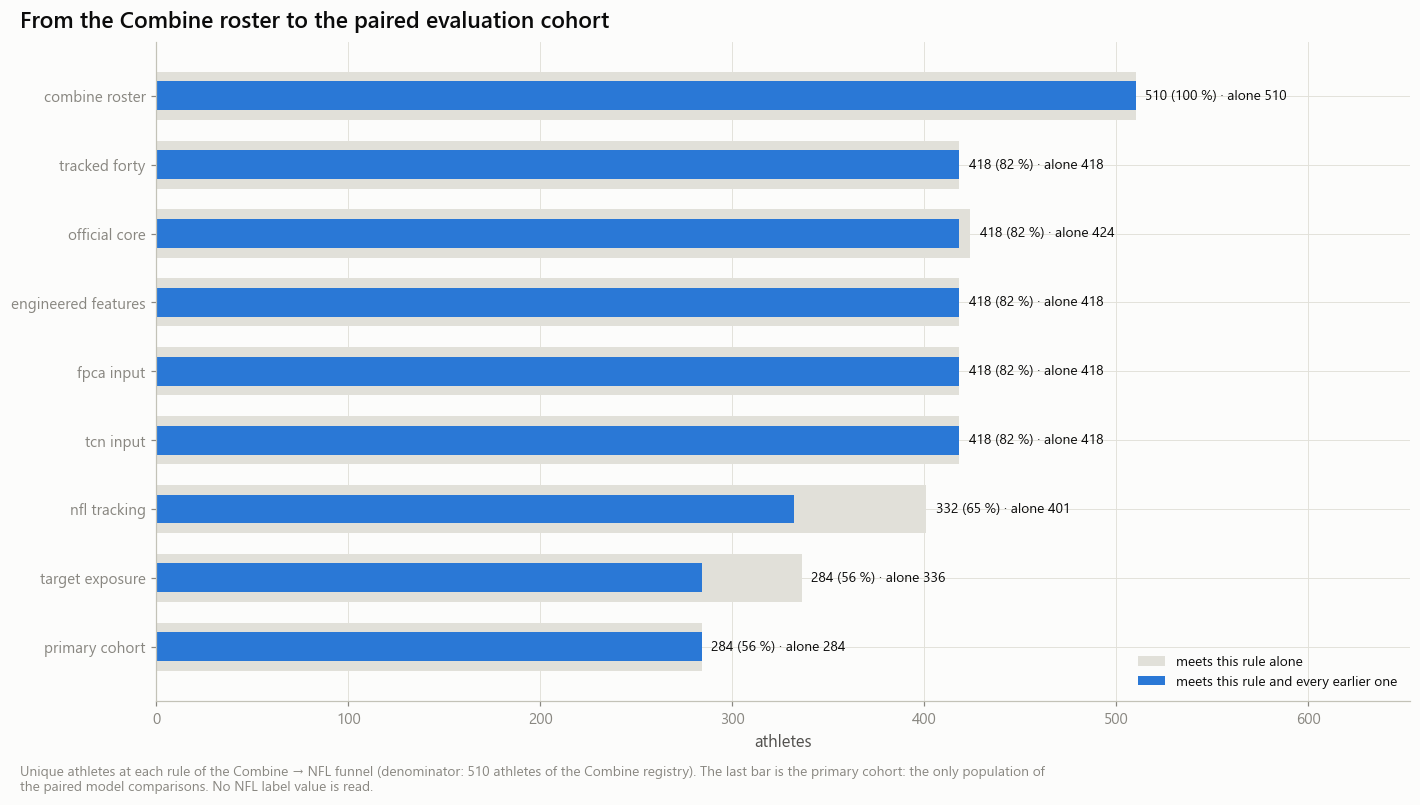

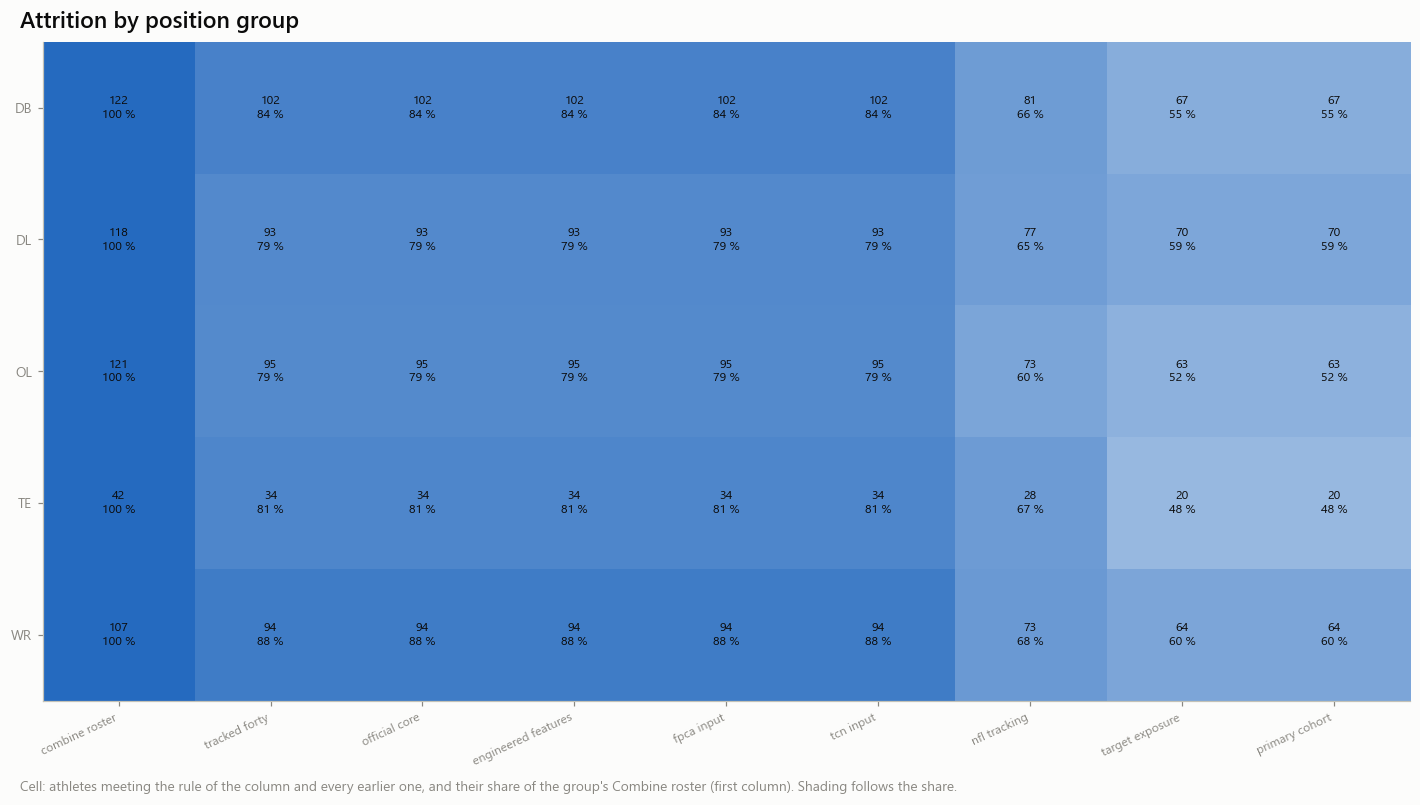

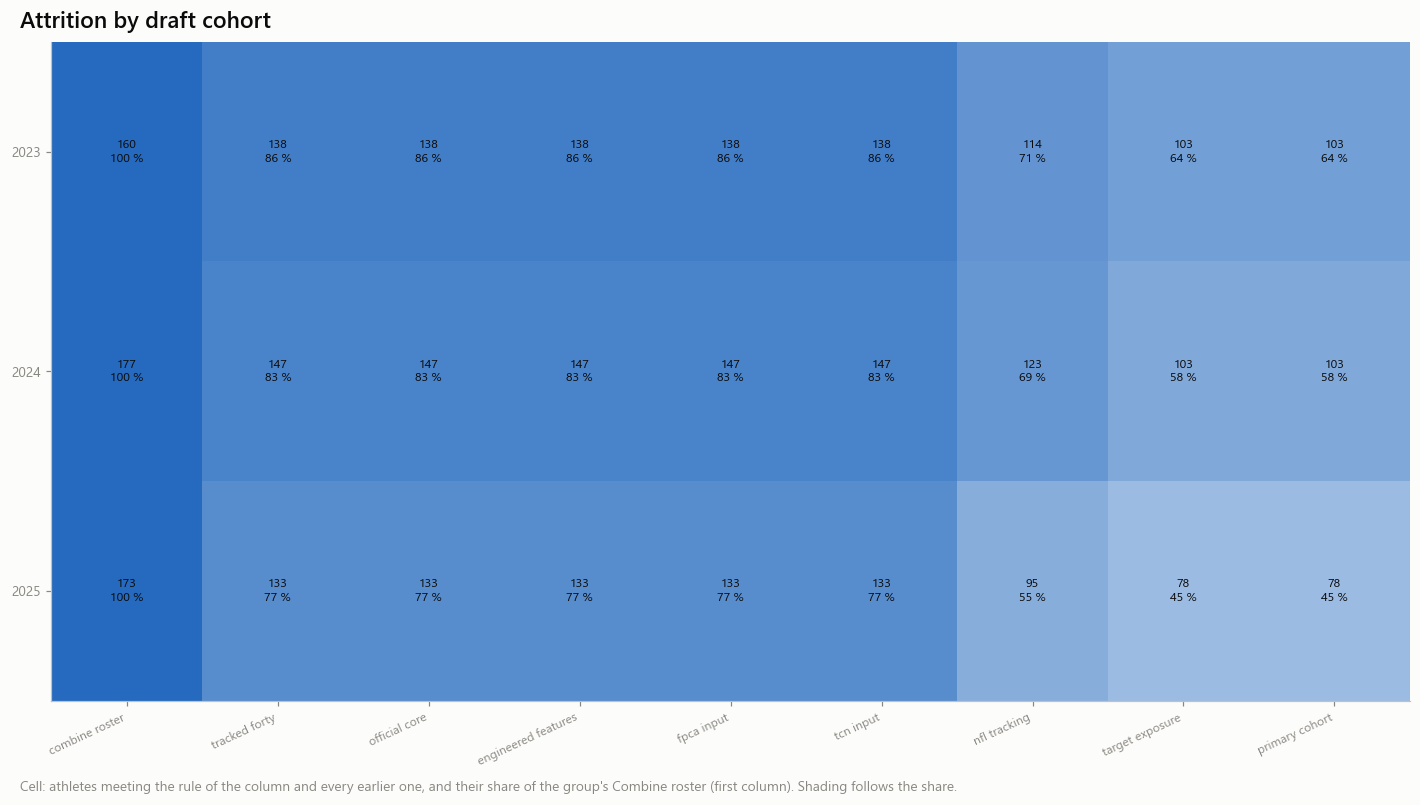

In [22]:
SRC = 'transfer_cohort_manifest (notebook 06A)'
store.show(tf.plot_funnel(funnel), 'AM06A_01_combine_to_nfl_cohort_funnel', {'funnel': funnel.filter(pl.col('group_type') == tr.ALL)},
           publication=True, source=SRC, n=f'{cohort.height} Combine athletes, {N_PRIMARY} in the primary cohort')
store.show(tf.plot_attrition(funnel, 'position_group', 'Attrition by position group'), 'AM06A_02_attrition_by_position',
           {'funnel': funnel.filter(pl.col('group_type') == 'position_group')}, source=SRC, n=f'{cohort.height} Combine athletes')
store.show(tf.plot_attrition(funnel, 'draft_year', 'Attrition by draft cohort'), 'AM06A_03_attrition_by_draft_year',
           {'funnel': funnel.filter(pl.col('group_type') == 'draft_year')}, source=SRC, n=f'{cohort.height} Combine athletes')

## 7. Missing-data policy

Official tests are often not performed. The policy is fixed here, from **coverage only**:

| Kind | Variables | Rule |
|---|---|---|
| mandatory official core | forty, 10-yard split, weight | an athlete without one is in no cohort; never imputed |
| body | height | training-fold median + missingness indicator |
| optional tests / body | vertical, broad jump, shuttle, three-cone, bench; hand, arm, wing span | enter M0 / M1 with training-fold median + indicator **only if** coverage among target-exposed athletes reaches the declared minimum; otherwise left out |
| engineered features, speed control | frozen shortlist ids | mandatory; missing means the tracking did not record the interval — never imputed |
| learned representations | FPCA scores, TCN embeddings | never imputed: no valid curve, no fingerprint, no place in the primary cohort |

The source cannot tell *did not participate* from *not reported*: both read as `no_value_recorded`. A column that does not exist, or is empty for a whole group, reads `field_unavailable`. A tracked feature without a value reads `tracking_insufficient` with the recorded reason.

11:10:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_missingness_audit: 270 rows → warehouse/gold/advanced_movement/transfer/transfer_missingness_audit.parquet


**Missingness among target-exposed athletes, and the rule applied** (unit: athlete)

variable,kind,n_athletes,n_missing,share_missing,missing_class,in_model,rule
str,str,i64,i64,f64,str,str,str
"""cmb_combine_height""","""body""",336,0,0.0,"""complete""","""imputed_with_indicator""","""training-fold median + missingness indicator"""
"""F2.forty.p95_speed""","""engineered""",284,0,0.0,"""complete""","""mandatory""","""an athlete without a measured value is not in the primary cohort; never imputed"""
"""F2.forty.peak_speed_interior""","""engineered""",284,0,0.0,"""complete""","""mandatory""","""an athlete without a measured value is not in the primary cohort; never imputed"""
"""F6.forty.time_v4_to_v8_s""","""engineered""",284,0,0.0,"""complete""","""mandatory""","""an athlete without a measured value is not in the primary cohort; never imputed"""
"""cmb_forty""","""official_core""",336,49,0.145833,"""no_value_recorded""","""mandatory""","""an athlete without it is not in the primary or wide cohort; never imputed"""
"""cmb_ten_yd_split""","""official_core""",336,49,0.145833,"""no_value_recorded""","""mandatory""","""an athlete without it is not in the primary or wide cohort; never imputed"""
"""cmb_combine_weight""","""official_core_body""",336,0,0.0,"""complete""","""mandatory""","""an athlete without it is not in the primary or wide cohort; never imputed"""
"""cmb_arm_length""","""optional_body""",336,0,0.0,"""complete""","""imputed_with_indicator""","""coverage 1.00 ≥ 0.5 among target-exposed athletes: training-fold median + missingness indicator"""
"""cmb_hand_size""","""optional_body""",336,0,0.0,"""complete""","""imputed_with_indicator""","""coverage 1.00 ≥ 0.5 among target-exposed athletes: training-fold median + missingness indicator"""


**M0 numeric predictors:** ['cmb_combine_weight', 'cmb_combine_height', 'cmb_hand_size', 'cmb_arm_length', 'cmb_wing_span']  
**M1 numeric predictors:** ['cmb_combine_weight', 'cmb_combine_height', 'cmb_hand_size', 'cmb_arm_length', 'cmb_wing_span', 'cmb_forty', 'cmb_ten_yd_split', 'cmb_vertical', 'cmb_broad_jump']  
**With a missingness indicator:** ['cmb_combine_height', 'cmb_hand_size', 'cmb_arm_length', 'cmb_wing_span', 'cmb_vertical', 'cmb_broad_jump']  
**Left out for low coverage:** ['cmb_bench_reps', 'cmb_short_shuttle', 'cmb_three_cone']  
Position group (unpenalised) and draft cohort are categorical predictors of every model from M0 on.

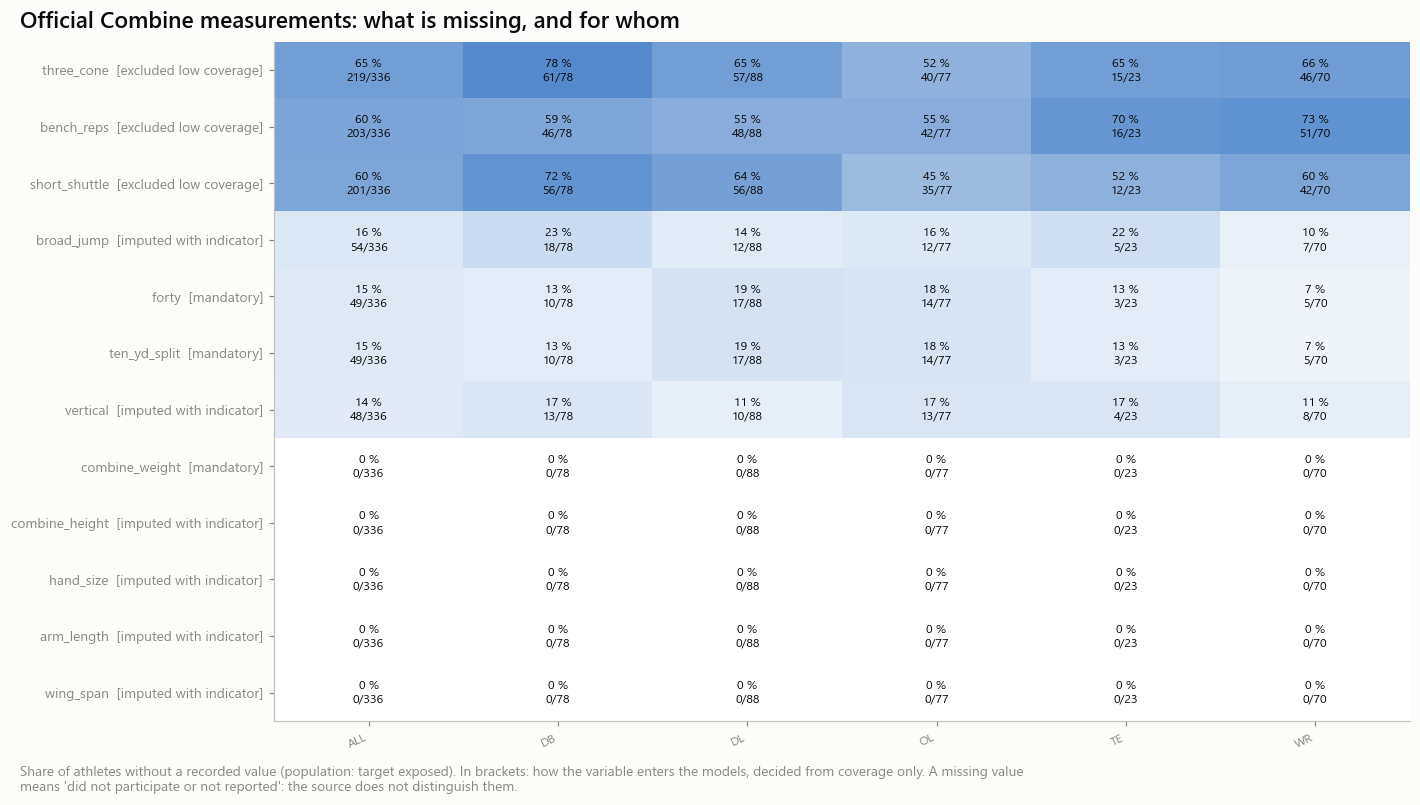

In [23]:
missing = save(tr.missingness_audit(official, cohort, attempt_values, mart.columns, families, tc), tr.MISSING)
design_columns = tr.official_design(missing, tc)
display(Markdown('**Missingness among target-exposed athletes, and the rule applied** (unit: athlete)'))
with pl.Config(tbl_rows=30, fmt_str_lengths=150):
    display(missing.filter((pl.col('population') == 'target_exposed') & (pl.col('group_type') == tr.ALL))
            .select('variable', 'kind', 'n_athletes', 'n_missing', 'share_missing', 'missing_class', 'in_model', 'rule').sort('kind', 'variable'))
display(Markdown(f'**M0 numeric predictors:** {design_columns["m0_numeric"]}  \n**M1 numeric predictors:** {design_columns["m1_numeric"]}  \n'
                 f'**With a missingness indicator:** {design_columns["indicators"]}  \n**Left out for low coverage:** {design_columns["excluded"]}  \n'
                 'Position group (unpenalised) and draft cohort are categorical predictors of every model from M0 on.'))
store.show(tf.plot_missingness(missing), 'AM06A_04_official_test_missingness', {'missing': missing.filter(pl.col('population') == 'target_exposed')},
           publication=True, source='transfer_missingness_audit', n=f'{int(cohort["st_target"].sum())} target-exposed athletes')

## 8. NFL exposure and temporal interpretation

Draft cohorts have been followed for different lengths of time, and tracking coverage changed between seasons. An outcome pooled over all seasons therefore rests on more games for older cohorts. This is **reported**, not corrected, in the primary analysis; notebook 06C repeats the benchmark on a common post-draft horizon (rookie season) and on the first N windows. The pre-draft cohort is never conditioned on later career success: an athlete enters with the frozen minimum exposure, whatever came after.

The last table counts how many primary-cohort athletes would remain under each alternative exposure rule — counts only, so the feasibility of the sensitivity analyses is known before any result exists.

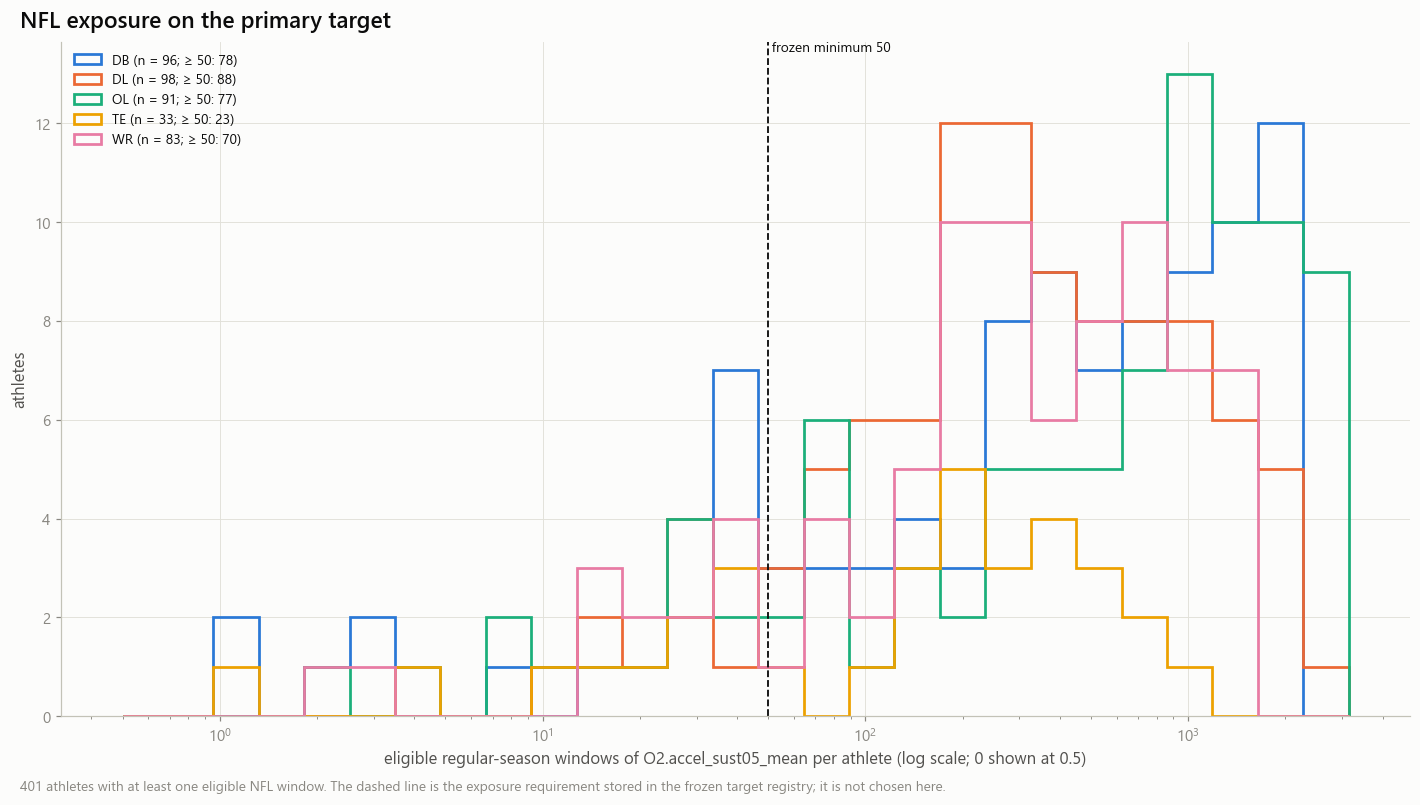

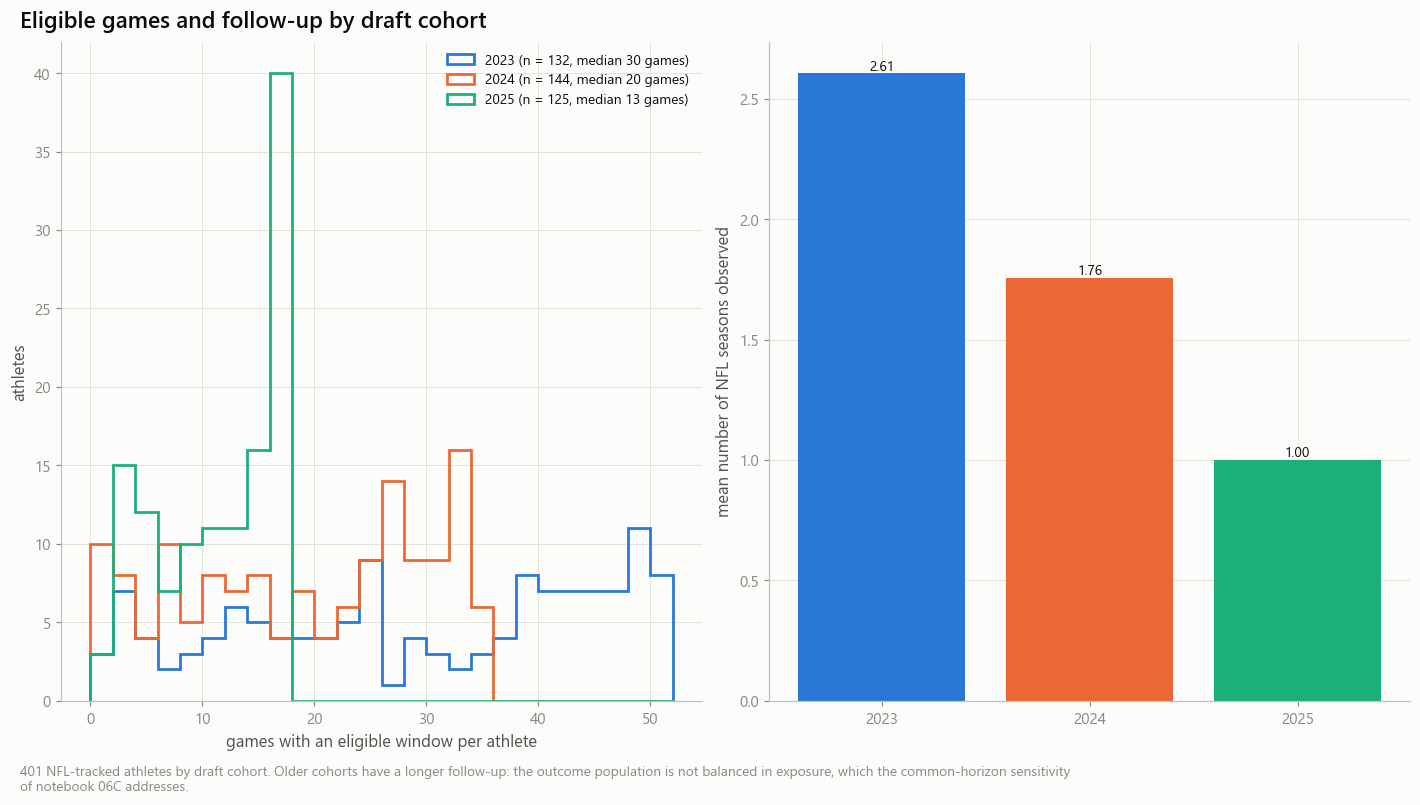

**Follow-up of the primary cohort by draft cohort** (unit: athlete)

draft_year,n_athletes,mean_seasons,median_games,median_target_windows,first_season,last_season
i64,u32,f64,f64,f64,i64,i64
2023,103,2.737864,32.0,701.0,2023,2025
2024,103,1.854369,24.0,593.0,2024,2025
2025,78,1.0,14.0,279.5,2025,2025


**Primary-cohort athletes under each declared exposure rule** (frozen rule: ≥ 50 windows; minimum to evaluate: 40)

exposure_rule,n_primary_cohort_athletes,evaluable_in_06C
str,i64,bool
"""≥ 20 windows (all seasons)""",284,true
"""≥ 50 windows (all seasons)""",284,true
"""≥ 100 windows (all seasons)""",250,true
"""≥ 200 windows (all seasons)""",218,true
"""first 50 windows in time""",284,true
"""first 100 windows in time""",250,true
"""first 200 windows in time""",218,true
"""first 1 season(s) after the dr…",252,true
"""≥ 4 games""",275,true


In [24]:
store.show(tf.plot_exposure(cohort, primary.min_windows, primary.target_id), 'AM06A_05_nfl_outcome_exposure_distribution',
           {'cohort': cohort.select('nfl_id', 'position_group', 'target_windows', 'st_nfl')}, publication=True, source=SRC,
           n=f'{int(cohort["st_nfl"].sum())} NFL-tracked athletes')
store.show(tf.plot_games(cohort), 'AM06A_06_eligible_game_count_distribution',
           {'cohort': cohort.select('nfl_id', 'draft_year', 'n_nfl_games', 'n_nfl_seasons', 'st_nfl')}, source=SRC,
           n=f'{int(cohort["st_nfl"].sum())} NFL-tracked athletes')

follow = (cohort.filter(pl.col('in_primary_cohort')).group_by('draft_year')
          .agg(pl.len().alias('n_athletes'), pl.col('n_nfl_seasons').mean().alias('mean_seasons'), pl.col('n_nfl_games').median().alias('median_games'),
               pl.col('target_windows').median().alias('median_target_windows'), pl.col('first_season').min().alias('first_season'),
               pl.col('last_season').max().alias('last_season')).sort('draft_year'))
display(Markdown('**Follow-up of the primary cohort by draft cohort** (unit: athlete)'))
display(follow)

prim_ids = cohort.filter(pl.col('in_primary_cohort'))['nfl_id'].to_numpy()
at_idx = np.searchsorted(tset.ids, prim_ids)
rows = []
for variant, need, what in ([('all', w, f'≥ {w} windows (all seasons)') for w in tc.exposure_min_windows]
                            + [(f'first_n:{k}', k, f'first {k} windows in time') for k in tc.first_n_windows]
                            + [(f'horizon:{h}', primary.min_windows, f'first {h} season(s) after the draft year, ≥ {primary.min_windows} windows') for h in tc.horizon_seasons]):
    n_w = tset.athlete_values(primary.target_id, variant=variant, adjustment='none')['n_windows'][at_idx]      # counts only
    rows.append({'exposure_rule': what, 'n_primary_cohort_athletes': int((n_w >= need).sum()),
                 'evaluable_in_06C': bool((n_w >= need).sum() >= tc.min_athletes)})
for g in tc.min_games:
    n_g = tset.athlete_values(primary.target_id, variant='all', adjustment='none')['n_games'][at_idx]
    rows.append({'exposure_rule': f'≥ {g} games', 'n_primary_cohort_athletes': int((n_g >= g).sum()), 'evaluable_in_06C': bool((n_g >= g).sum() >= tc.min_athletes)})
exposure_rules = pl.DataFrame(rows)
display(Markdown(f'**Primary-cohort athletes under each declared exposure rule** (frozen rule: ≥ {primary.min_windows} windows; minimum to evaluate: {tc.min_athletes})'))
display(exposure_rules)

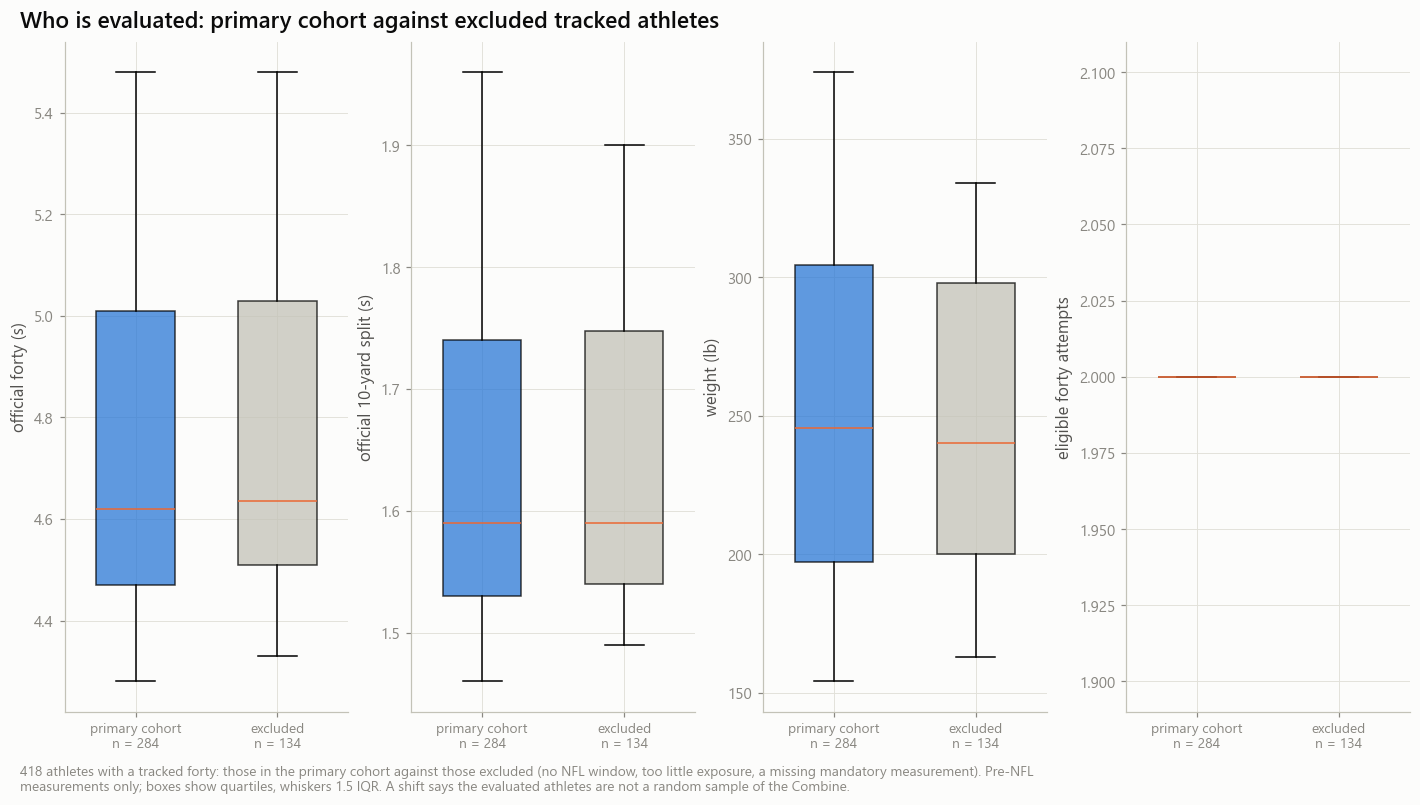

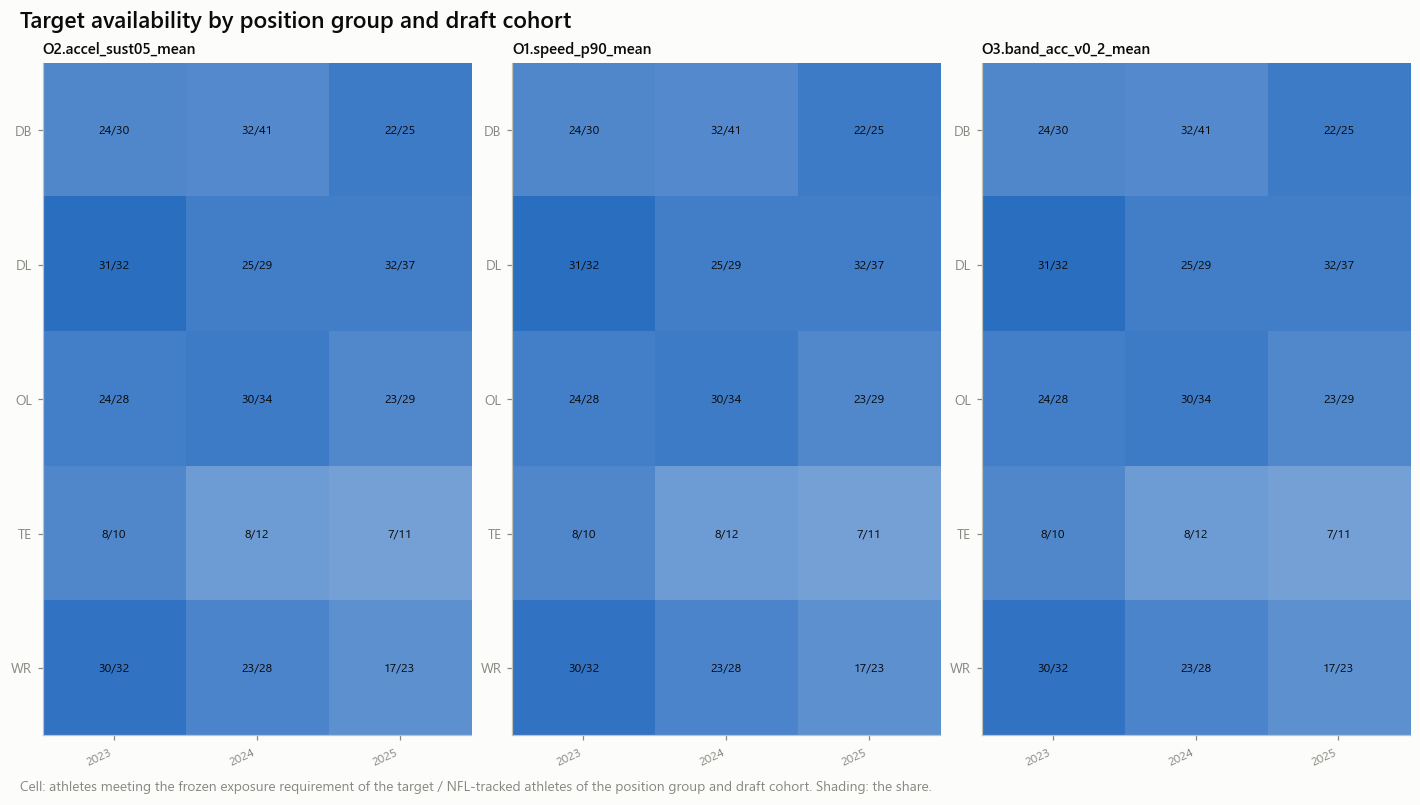

**Pre-NFL measurements: primary cohort against excluded tracked athletes** (unit: athlete; no NFL value)

in_primary_cohort,n,mean_cmb_forty,mean_cmb_ten_yd_split,mean_cmb_combine_weight,mean_attempts
bool,u32,f64,f64,f64,f64
true,284,4.728873,1.631796,247.950704,1.887324
false,134,4.753806,1.635746,242.88806,1.91791


In [25]:
VARS = [(fe.FORTY, 'official forty (s)'), (fe.TEN, 'official 10-yard split (s)'), (fe.WEIGHT, 'weight (lb)')]
store.show(tf.plot_included_vs_excluded(cohort, official, VARS), 'AM06A_07_analytical_cohort_vs_excluded', publication=True,
           source=SRC + ' + official Combine measurements', n=f'{int(cohort["st_tracked"].sum())} athletes with a tracked forty')
store.show(tf.plot_target_availability(eligibility, cohort), 'AM06A_08_target_availability_by_position_and_cohort',
           {'eligibility': eligibility.join(cohort.select('nfl_id', 'position_group', 'draft_year'), on='nfl_id', how='left')},
           source='transfer_target_eligibility', n=f'{int(cohort["st_nfl"].sum())} NFL-tracked athletes')

tracked = cohort.filter(pl.col('st_tracked')).join(official, on='nfl_id', how='left')
display(Markdown('**Pre-NFL measurements: primary cohort against excluded tracked athletes** (unit: athlete; no NFL value)'))
display(tracked.group_by('in_primary_cohort').agg(pl.len().alias('n'), *[pl.col(c).mean().alias(f'mean_{c}') for c, _ in VARS],
                                                  pl.col('n_attempts').mean().alias('mean_attempts')).sort('in_primary_cohort', descending=True))

## 9. Split integrity

Outer folds are athlete-grouped and stratified by position group × draft cohort. Two designs are considered, in this order, **on athlete counts only**:

1. `registry` — the outer folds of the notebook-00 split registry (repeat 0). These are the folds every saved FPCA and TCN fit was made under; reusing them is what makes a saved encoder usable.
2. `new_<K>` — new stratified folds with the largest K of the declared grid meeting the size rules. Every saved encoder then becomes descriptive-only and 06B refits them.

Size rules (declared in `TransferConfig`): a minimum number of held-out athletes per fold, and a minimum number of training athletes of each position group in every fold. Five folds are used only if they are viable. The inner fold (ridge penalty) is a second, independent label used inside each training set.

All Combine attempts of an athlete share his fold; his label is one value, so all his NFL seasons follow it.

11:10:35 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_outer_folds: 287 rows → warehouse/gold/advanced_movement/transfer/transfer_outer_folds.parquet
11:10:35 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_fold_candidates: 4 rows → warehouse/gold/advanced_movement/transfer/transfer_fold_candidates.parquet


**Fold designs considered**

candidate,n_folds,min_heldout,max_heldout,min_position_train,smallest_cell,viable,selected,reason
str,i64,i64,i64,i64,str,bool,bool,str
"""registry""",5,54,59,15,"""TE outside fold 0""",true,true,"""size rules met (note: TE|2025 absent from fold 4)"""
"""new_5""",5,56,57,16,"""TE outside fold 0""",true,false,"""size rules met"""
"""new_4""",4,71,71,15,"""TE outside fold 0""",true,false,"""size rules met"""
"""new_3""",3,94,95,13,"""TE outside fold 0""",true,false,"""size rules met"""


**Retained: `registry`, 5 outer folds** · manifest hash `142da5600e6da0f4`

- 287 athletes, one outer fold each (5 folds, source registry)
- all eligible Combine attempts of an athlete share his encoder fold
- the encoder fold and the prediction fold of every linked athlete are the same fold
- NFL labels are one value per athlete, so all his seasons follow his fold by construction

**Held-out athletes of the primary cohort by fold and position group**

outer_fold,DL,OL,WR,TE,DB
i64,u32,u32,u32,u32,u32
0,12,16,14,5,11
1,15,14,10,4,11
2,11,11,13,4,17
3,16,11,14,4,14
4,16,11,13,3,14


**… and by draft cohort**

outer_fold,2023,2024,2025
i64,u32,u32,u32
0,21,20,17
1,20,20,14
2,21,21,14
3,20,21,18
4,21,21,15


**Encoder split table:** 418 tracked athletes; 0 are never held out (tracked, not in a transfer fold: their unlabelled Combine attempts take part in every encoder fit).

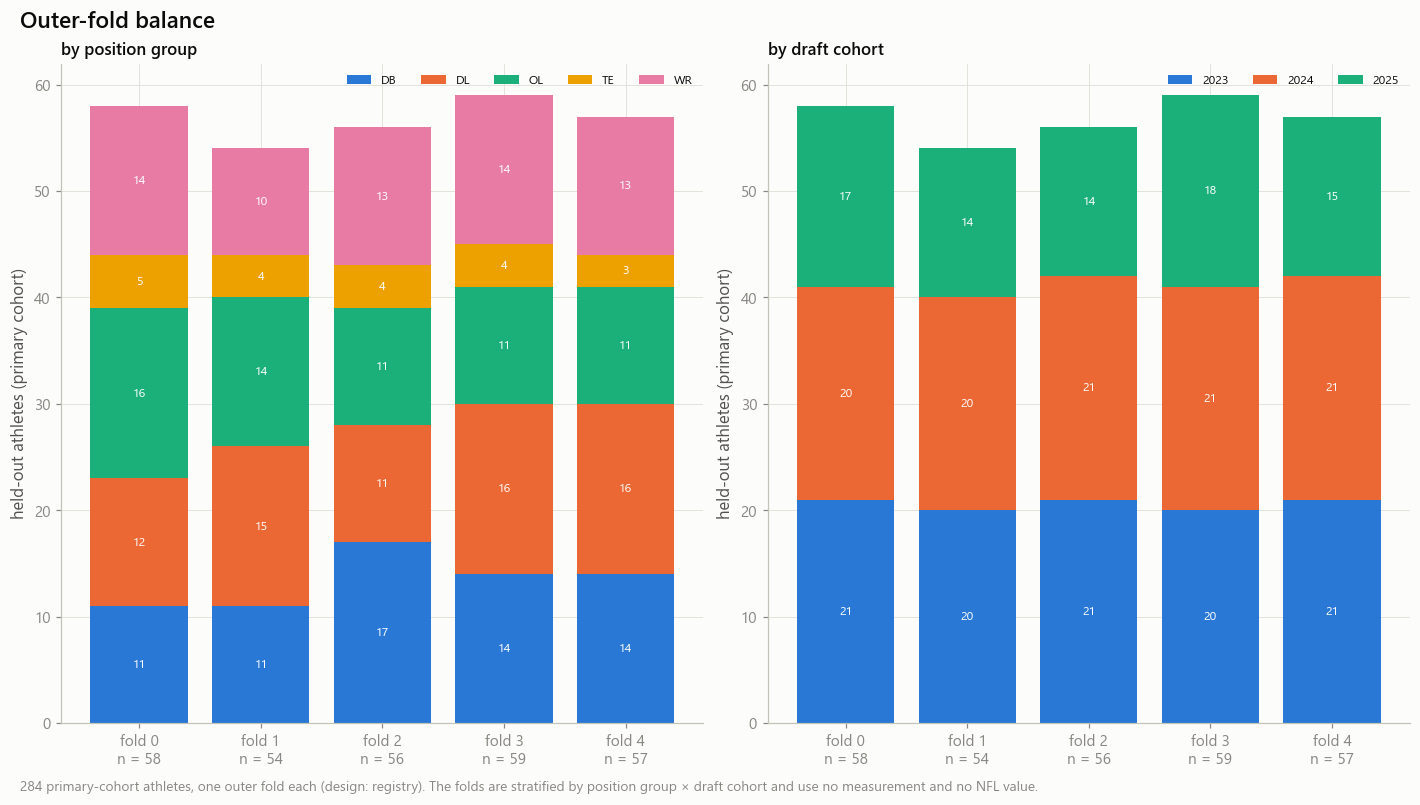

In [26]:
folds, fold_plan = tr.assign_folds(cohort, splits, tc, source=FOLD_SOURCE)
folds, fold_plan = save(folds, tr.FOLDS), save(fold_plan, tr.FOLD_PLAN)
enc_splits = tr.encoder_splits(folds, splits)
integrity = tr.assert_fold_integrity(folds, enc_splits, manifest)
FOLDS_HASH = tr.folds_hash(folds)

display(Markdown('**Fold designs considered**'))
with pl.Config(fmt_str_lengths=200):
    display(fold_plan)
display(Markdown(f'**Retained: `{folds["fold_source"][0]}`, {folds["n_folds"][0]} outer folds** · manifest hash `{FOLDS_HASH}`\n\n'
                 + '\n'.join(f'- {s}' for s in integrity)))
prim_folds = folds.filter(pl.col('in_primary_cohort'))
display(Markdown('**Held-out athletes of the primary cohort by fold and position group**'))
display(prim_folds.group_by('outer_fold', 'position_group').len().pivot(on='position_group', index='outer_fold', values='len').sort('outer_fold'))
display(Markdown('**… and by draft cohort**'))
display(prim_folds.group_by('outer_fold', 'draft_year').len().pivot(on='draft_year', index='outer_fold', values='len').sort('outer_fold'))
never = enc_splits.filter(pl.col('outer_fold') < 0).height
display(Markdown(f'**Encoder split table:** {enc_splits.height} tracked athletes; {never} are never held out (tracked, not in a transfer fold: '
                 'their unlabelled Combine attempts take part in every encoder fit).'))
store.show(tf.plot_fold_balance(folds), 'AM06A_09_fold_population_balance', {'folds': prim_folds}, source='transfer_outer_folds',
           n=f'{prim_folds.height} primary-cohort athletes')

## 10. Representation leakage audit — critical

An embedding called *out of fold* in notebook 03 is out of fold **for the folds of notebook 03**. Whether it is out of fold for the transfer evaluation is a property of the transfer folds, and is checked per saved model:

- every saved TCN checkpoint (notebook 03 and the seed replicates of 04B) is opened and the athletes that touched it are read from the file: weights, early stopping **and** input normalisation;
- every saved FPCA fit of the benchmark input is read with its fitting athletes;
- a fit is `compatible` for transfer fold *f* only if it was made for split repeat 0, fold *f*, and **none** of its athletes is held out in transfer fold *f*;
- all-athlete reference fits, fits of other split repeats, and every fit when the folds are new are `descriptive_only`: they are never predictors in 06B, which refits on training athletes.

Choices made earlier on Combine data alone (the TCN-B consistency term, the FPCA K, the shortlist) are listed as `combine_only_selection`: no NFL value was involved, and they are kept as frozen. The saved all-athlete embedding tables are **not** loaded by 06B: embeddings are recomputed from the audited encoders.

11:10:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] representation_checkpoint_compatibility: 51 rows → warehouse/gold/advanced_movement/transfer/representation_checkpoint_compatibility.parquet


**46 saved fit(s) of input `A_speed_by_distance` audited** — 35 compatible, 11 descriptive_only

family,method,repeat,fold,n_fit_athletes,n_heldout_transfer,n_overlap,status,use,note
str,str,i64,i64,i64,i64,i64,str,str,str
"""fpca""","""FPCA:r0_f0""",0,0,334,59,0,"""compatible""","""reusable in 06B for this fold""","""no held-out transfer athlete took part in the fit"""
"""fpca""","""FPCA:r0_f1""",0,1,334,55,0,"""compatible""","""reusable in 06B for this fold""","""no held-out transfer athlete took part in the fit"""
"""fpca""","""FPCA:r0_f2""",0,2,334,57,0,"""compatible""","""reusable in 06B for this fold""","""no held-out transfer athlete took part in the fit"""
"""fpca""","""FPCA:r0_f3""",0,3,335,59,0,"""compatible""","""reusable in 06B for this fold""","""no held-out transfer athlete took part in the fit"""
"""fpca""","""FPCA:r0_f4""",0,4,335,57,0,"""compatible""","""reusable in 06B for this fold""","""no held-out transfer athlete took part in the fit"""
"""fpca""","""FPCA:r1_f0""",1,0,334,287,226,"""descriptive_only""","""not used as a predictor""","""another split repeat: no transfer fold corresponds to it"""
"""fpca""","""FPCA:r1_f1""",1,1,334,287,227,"""descriptive_only""","""not used as a predictor""","""another split repeat: no transfer fold corresponds to it"""
"""fpca""","""FPCA:r1_f2""",1,2,334,287,232,"""descriptive_only""","""not used as a predictor""","""another split repeat: no transfer fold corresponds to it"""
"""fpca""","""FPCA:r1_f3""",1,3,335,287,225,"""descriptive_only""","""not used as a predictor""","""another split repeat: no transfer fold corresponds to it"""


**Choices made on Combine data only** (no NFL value; kept as frozen)

artifact,note
str,str
"""TCN-B consistency term (kind, weight)""","""notebook 03 chose it on the DESIGN athletes' Combine attempts (cross-fitted); it returned the pre-declared default. No NFL value. Design ath…"
"""TCN architecture, optimiser and budget""","""fixed before any fit (TcnConfig); reused unchanged."""
"""FPCA number of components""","""smallest K with out-of-fold explained variance ≥ 0.95 on Combine curves (notebook 02). No NFL value."""
"""Frozen shortlist (engineered feature, speed control, compact dimension)""","""notebook 04B, by Combine reliability and redundancy on all tracked athletes. No NFL value; frozen before this milestone."""
"""Matching rule (variables, caliper, k)""","""notebook 04B MatchConfig; scales from design athletes. No NFL value."""


**Primary TCN-B fold encoders reusable in 06B:** folds [0, 1, 2, 3, 4] of [0, 1, 2, 3, 4]. Any other fold is trained in 06B on its training athletes with the frozen configuration.

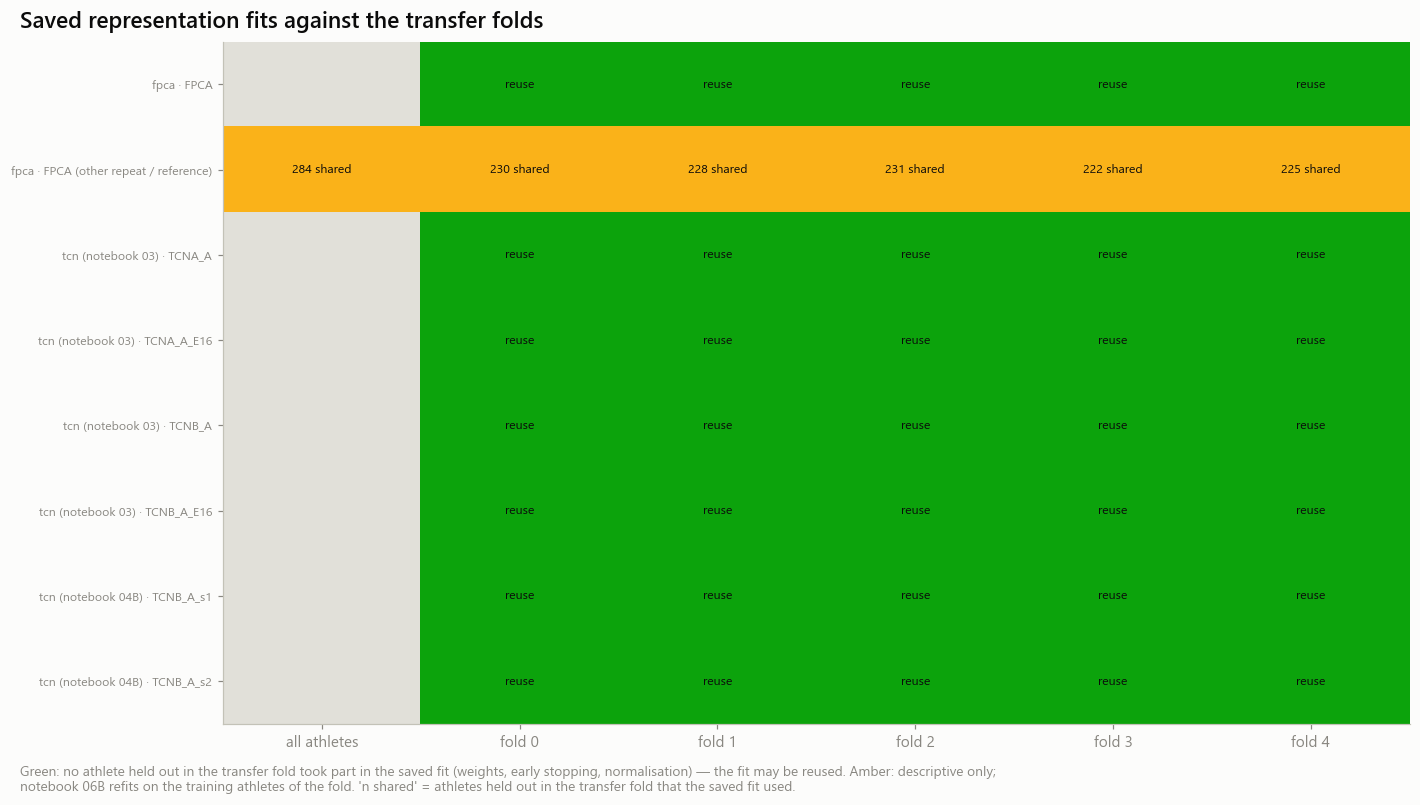

In [27]:
records = trp.checkpoint_records({'notebook 03': up.models_dir, 'notebook 04B': store.atlas.models_dir},
                                 fe.model_path(up.models_dir, PRIMARY_INPUT), PRIMARY_INPUT, rel)
compat = save(tr.compatibility_table(records, folds), tr.COMPAT)
saved_fits = compat.filter(pl.col('status') != 'combine_only_selection')
display(Markdown(f'**{len(records)} saved fit(s) of input `{PRIMARY_INPUT}` audited** — '
                 + (', '.join(f'{n} {s}' for s, n in saved_fits.group_by('status').len().sort('status').iter_rows()) or 'none found')))
with pl.Config(tbl_rows=60, fmt_str_lengths=140):
    display(saved_fits.select('family', 'method', 'repeat', 'fold', 'n_fit_athletes', 'n_heldout_transfer', 'n_overlap', 'status', 'use', 'note')
            .sort('family', 'method', 'repeat', 'fold'))
    display(Markdown('**Choices made on Combine data only** (no NFL value; kept as frozen)'))
    display(compat.filter(pl.col('status') == 'combine_only_selection').select('artifact', 'note'))
reuse_primary = tr.reusable_checkpoints(compat, 'TCNB_A')
display(Markdown(f'**Primary TCN-B fold encoders reusable in 06B:** folds {sorted(reuse_primary)} of {sorted(prim_folds["outer_fold"].unique().to_list())}. '
                 'Any other fold is trained in 06B on its training athletes with the frozen configuration.'))
store.show(tf.plot_compatibility(compat), 'AM06A_10_representation_checkpoint_compatibility', {'compatibility': compat}, publication=True,
           source='representation_checkpoint_compatibility', n=f'{len(records)} saved fits, {folds["n_folds"][0]} transfer folds')

## 11. Gate 06A — data integrity

Pass only if: the target registry is frozen · athlete linkage is valid · evaluation folds are viable · the common cohort is documented and large enough · every representation leakage risk is resolved (reusable) or the affected fit is excluded (descriptive-only, refitted in 06B).

The manifest written here is what notebooks 06B and 06C verify before fitting anything: the hash of the frozen targets and the hash of the fold table. If either changes later, they refuse to run.

In [28]:
gate = save(tr.gate_06a(freeze_audit, identity, cohort, folds, fold_plan, compat, tc).with_columns(), tr.GATE)
GATE_STATUS = 'PASS' if gate['passed'].all() else 'FAIL'
with pl.Config(fmt_str_lengths=220):
    display(gate)

if controls.save_tables:
    store.write_json(tr.INPUT_CONTRACT, {
        'notebook': PROV['notebook'], 'inputs': inputs, 'primary_input': PRIMARY_INPUT, 'fpca_k': FPCA_K, 'families': families,
        'design_columns': design_columns, 'targets': [t.__dict__ for t in targets], 'outcome_config': ocfg.params(),
        'outcome_definition_hash': no.definition_hash(ocfg), 'target_grain': 'athlete: frozen statistic over all eligible regular-season windows',
        'outputs': [c.name for c in (tr.IDENTITY, tr.ELIGIBILITY, tr.COHORT, tr.FUNNEL, tr.COUNTS, tr.REASONS, tr.MISSING, tr.FOLDS,
                                     tr.FOLD_PLAN, tr.COMPAT, tr.GATE)]})
    store.write_json(tr.AUDIT_MANIFEST, {
        'notebook': PROV['notebook'], 'status': 'executed', 'gate_06a': GATE_STATUS, 'seed': controls.seed, 'transfer_config': tc.params(),
        'targets_version_hash': registry_doc['version_hash'], 'targets_frozen_at': registry_doc['frozen_at'], 'primary_target': primary.target_id,
        'targets': [t.target_id for t in targets], 'folds_hash': FOLDS_HASH, 'fold_source': folds['fold_source'][0], 'n_folds': int(folds['n_folds'][0]),
        'n_roster': cohort.height, 'n_primary_cohort': N_PRIMARY, 'n_wide_cohort': N_WIDE, 'n_identity_conflicts': len(bad_identity),
        'reusable_primary_encoder_folds': sorted(reuse_primary), 'n_saved_fits_audited': len(records), 'audited_at': utc_now(),
        'validation': validation_report.to_dicts(), 'predictions_computed': False})
tr.assert_gate(gate, '06A')
display(Markdown(f'### Gate 06A: {GATE_STATUS}\n{N_PRIMARY} athletes · {folds["n_folds"][0]} outer folds ({folds["fold_source"][0]}) · primary target '
                 f'`{primary.target_id}` · no prediction and no Combine ↔ NFL association was computed in this notebook.'))

11:10:41 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06A] transfer_gate: 5 rows → warehouse/gold/advanced_movement/transfer/transfer_gate.parquet


criterion,passed,detail
str,bool,str
"""target_registry_frozen""",true,"""13 checks of the registry"""
"""athlete_linkage_valid""",true,"""every critical identity check passed"""
"""evaluation_folds_viable""",true,"""registry: 5 folds over 284 primary-cohort athletes"""
"""common_cohort_documented""",true,"""284 athletes support every model M0–M7 (minimum 40)"""
"""representation_leakage_resolved""",true,"""35 saved fit(s) reusable, 11 descriptive-only (refitted on training athletes in 06B)"""


### Gate 06A: PASS
284 athletes · 5 outer folds (registry) · primary target `O2.accel_sust05_mean` · no prediction and no Combine ↔ NFL association was computed in this notebook.

## 12. What this notebook established, and what comes next

- **Established here (after you run it):** the frozen targets, the linked athletes, the primary and wide cohorts with every exclusion reason, the missing-data rules, the folds, and which saved encoders may be reused.
- **Not established here:** anything about whether Combine movement predicts NFL movement. No label value was joined to a Combine value.

**Outputs** (`…/advanced_movement/transfer/`, smoke: `…/_sample/transfer/`): `transfer_cohort_manifest.parquet`, `transfer_cohort_funnel.csv`, `transfer_position_cohort_counts.csv`, `transfer_eligibility_reasons.csv`, `transfer_missingness_audit.csv`, `transfer_outer_folds.parquet` + `.csv`, `transfer_fold_candidates.csv`, `representation_checkpoint_compatibility.csv`, `transfer_identity_audit.csv`, `transfer_target_eligibility.parquet`, `transfer_gate.csv`, `transfer_input_contract.json`, `transfer_cohort_audit_manifest.json`, figures `AM06A_01`–`AM06A_10`.

**Next:** `06b_combine_to_nfl_transfer_benchmark.ipynb` in the same `RUN_MODE`. Do not change the fold table or re-freeze the targets between 06A and 06B; if you must, rerun 06A first.